# Agnostic Fundamental Analysis（Bartram–Grinblatt 2018）の評価

各月、非金融銘柄の時価総額 $V$ を財務項目の水準に横断面回帰して公正価値 $P$ を推定し、乖離率 $M=(P-V)/V$（高いほど割安）をスコアにした `agnostic/afa_*` を評価する。
モデルは 7 本: 論文どおりの in-sample OLS（`ols_is`）、論文の Theil–Sen 型（`ts`）、交差推定の OLS・Ridge・Lasso（水準）、Random Forest・LightGBM（log 時価総額）。生成方法は `input/msci_india_imi/alpha/agnostic/README.md`。

確認すること:

1. **当てはまり**: 公正価値が時価総額をどれだけ説明しているか（月次）
2. **スタイル**: 生のスコアはサイズと強く逆相関する（小型ほど「割安」）。サイズ・セクター中立化版（`agnostic_neu`）と比べる
3. **単独の予測力と持続性**: IC と IC の減衰（論文では効果が約 34 か月続く）
4. **comp_ew への上乗せ**: 残差 IC、スパニング回帰、comp_ew との複合
5. **長期保有版**: 中立化版の 12 か月平均（`agnostic_smooth`、論文の 1 年保有戦略の近似）の回転率と税控除後の成績

スコアの生成コマンド（実行済み）:

```bash
uv run python scripts/build_agnostic.py --n-jobs 8
for m in ols_is ts ols ridge lasso rf lgbm; do
  uv run python scripts/build_neutralize.py --score agnostic/afa_$m --size --sector --name afa_${m}_neu --group agnostic_neu --start 200801 --end 202607
  uv run python scripts/build_smooth.py --score agnostic_neu/afa_${m}_neu --window 12 --name afa_${m}_neu_avg12 --group agnostic_smooth --start 200801 --end 202607
done
for pair in agnostic_smooth/afa_ts_neu_avg12:afats12 agnostic_neu/afa_ts_neu:afats agnostic_neu/afa_lgbm_neu:afalgbm agnostic_neu/afa_rf_neu:afarf; do
  uv run python scripts/build_blend.py --score-a composite/comp_ew --score-b ${pair%%:*} --weights 90 80 70 --name "comp_ew_{a}_${pair##*:}_{b}" --group composite --start 200801 --end 202606
done
```

**規約**: Healthy Compounder の評価（`experiments/healthy_compounder/02_incremental_vs_comp_ew`）と同じ（Q5 = 最上位、drtn 複利 / srtn 累和、税は信託・INR、コスト 15/25bp、バーンイン 12 か月、BM = MSCI India、2008-01 以降）。
金融セクターは afa のスコアが無いので、単独評価の分位は非金融銘柄だけで組まれる。複合スコアでは金融は comp_ew のスコアだけで並ぶ。

In [1]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # noqa: F401  日本語ラベル用
import numpy as np
import pandas as pd
from scipy.stats import norm

from alphaeval import InputStore, compute_alpha_report, ic_summary, india_tax_schedule, information_coefficient, plot_cross_alpha_bars, plot_cumulative, quantile_analysis, summary_table
from alphaeval.panel import forward_returns

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
MODELS = ["ols_is", "ts", "ols", "ridge", "lasso", "rf", "lgbm"]
CANDIDATES = ["ts_neu", "ts_neu12", "rf_neu", "lgbm_neu"]
TAGS = {"ts_neu12": "afats12", "ts_neu": "afats", "lgbm_neu": "afalgbm", "rf_neu": "afarf"}
W = [90, 80, 70]
BLENDS = {c: [f"comp_ew_{w}_{t}_{100 - w}" for w in W] for c, t in TAGS.items()}
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
START, END = 200801, 202606
N_QUANTILES = 5
CW_MAX_WEIGHT = 0.05
COST_BUY, COST_SELL = 0.0015, 0.0025
FPI_TYPE = "trust"
BURN_IN = 12

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)
load = lambda path: store.alpha(path, START, END).reindex(index=univ.index, columns=univ.columns).where(univ.notna())
paths = {"comp_ew": "composite/comp_ew"}
for m in MODELS:
    paths[m] = f"agnostic/afa_{m}"
    paths[f"{m}_neu"] = f"agnostic_neu/afa_{m}_neu"
    paths[f"{m}_neu12"] = f"agnostic_smooth/afa_{m}_neu_avg12"
for names in BLENDS.values():
    paths.update({n: f"composite/{n}" for n in names})
scores = {n: load(p) for n, p in paths.items()}
returns = {kind: store.returns(RISK_MODEL, col, START, 202607) for kind, col in RETURN_KINDS.items()}
fwd = {kind: forward_returns(r, 1) for kind, r in returns.items()}
fit_stats = pd.read_csv(f"{INPUT_ROOT}/alpha/agnostic/fit_stats.csv")


def blom(values: pd.DataFrame) -> pd.DataFrame:
    ranks = values.rank(axis=1)
    n = values.notna().sum(axis=1)
    return pd.DataFrame(norm.ppf(ranks.sub(0.375).div(n + 0.25, axis=0).to_numpy(dtype=float)), index=values.index, columns=values.columns)


def residualize(y: pd.DataFrame, x: pd.DataFrame) -> pd.DataFrame:
    # 各月、Blom(y) を定数 + Blom(x) に OLS 回帰した残差（両方そろう銘柄のみ）
    m = y.notna() & x.notna()
    yb, xb = blom(y.where(m)), blom(x.where(m))
    yc = yb.sub(yb.mean(axis=1), axis=0)
    xc = xb.sub(xb.mean(axis=1), axis=0)
    beta = (yc * xc).sum(axis=1) / (xc**2).sum(axis=1)
    return yc - xc.mul(beta, axis=0)


def row_rank_corr(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    m = a.notna() & b.notna()
    ra, rb = a.where(m).rank(axis=1), b.where(m).rank(axis=1)
    ra, rb = ra.sub(ra.mean(axis=1), axis=0), rb.sub(rb.mean(axis=1), axis=0)
    return (ra * rb).sum(axis=1) / np.sqrt((ra**2).sum(axis=1) * (rb**2).sum(axis=1))


def nw_ols(y: pd.Series, x: pd.Series, lags: int = 6) -> dict[str, float]:
    df = pd.concat([y, x], axis=1).dropna()
    Y = df.iloc[:, 0].to_numpy()
    X = np.column_stack([np.ones(len(df)), df.iloc[:, 1].to_numpy()])
    b = np.linalg.lstsq(X, Y, rcond=None)[0]
    e = Y - X @ b
    xtx_inv = np.linalg.inv(X.T @ X)
    S = (X * e[:, None]).T @ (X * e[:, None])
    for L in range(1, lags + 1):
        w = 1 - L / (lags + 1)
        G = (X[L:] * e[L:, None]).T @ (X[:-L] * e[:-L, None])
        S += w * (G + G.T)
    se = np.sqrt(np.diag(xtx_inv @ S @ xtx_inv))
    r2 = 1 - (e**2).sum() / ((Y - Y.mean()) ** 2).sum()
    return {"alpha (年率)": b[0] * 12, "alpha t": b[0] / se[0], "beta": b[1], "beta t": b[1] / se[1], "R2": r2}

## 1. 当てはまり

月別の水準の決定係数（R²）と、公正価値と時価総額の順位相関。交差推定のモデルは、自分の時価総額を学習に使わずに予測した値で測る。論文の in-sample R² は中央値 92.7%。

,n,r2_level,rank_corr,nonpos_share
model,,,,
ols_is,274.0,0.868,0.617,0.042
ts,274.0,0.872,0.701,0.027
ols,274.0,0.302,0.559,0.058
ridge,274.0,0.516,0.654,0.011
lasso,274.0,0.549,0.635,0.011
rf,274.0,0.274,0.709,0.000
lgbm,274.0,0.445,0.722,0.000


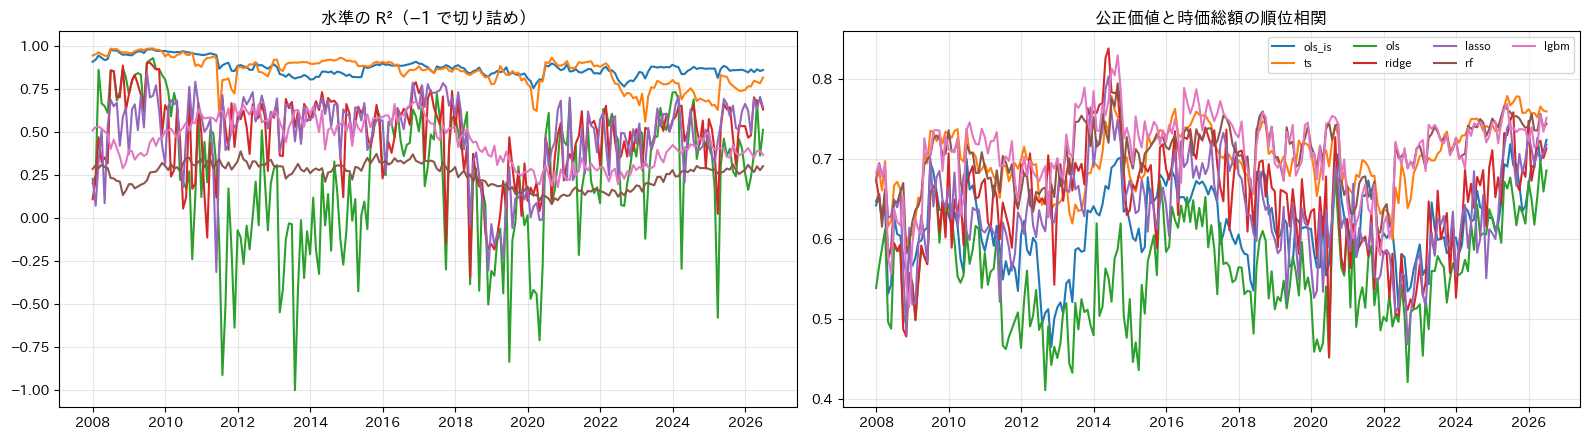

In [2]:
fs = fit_stats.assign(date=pd.to_datetime(fit_stats["yyyymm"].astype(str), format="%Y%m"))
display(fs.groupby("model")[["n", "r2_level", "rank_corr", "nonpos_share"]].median().loc[MODELS].round(3))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for m in MODELS:
    s = fs[fs["model"] == m].set_index("date")
    axes[0].plot(s.index, s["r2_level"].clip(lower=-1), label=m)
    axes[1].plot(s.index, s["rank_corr"], label=m)
axes[0].set_title("水準の R²（−1 で切り詰め）")
axes[1].set_title("公正価値と時価総額の順位相関")
axes[1].legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## 2. スタイルへの傾き

各月の順位相関の平均。生のスコアは $M=(P-V)/V$ の分母に時価総額があるうえ、定数項と予測の縮小で小型ほど「割安」に出やすい。

In [3]:
style = {"log size": np.log(univ.where(univ > 0)), **{c: store.alpha(f"core/{c}", START, END).reindex(index=univ.index, columns=univ.columns) for c in ["bp_act", "ep_act", "mom12_1", "vola60"]}}
bmw = bm.reindex(index=univ.index, columns=univ.columns)
rows = {}
for n in ["comp_ew"] + MODELS + [f"{m}_neu" for m in MODELS] + ["ts_neu12"]:
    s = scores[n]
    rows[n] = {**{f"corr({k})": float(row_rank_corr(s, v).mean()) for k, v in style.items()}, "corr(comp_ew)": float(row_rank_corr(s, scores["comp_ew"]).mean()), "BM 加重平均": float(((s * bmw).sum(axis=1) / bmw.where(s.notna()).sum(axis=1)).mean())}
display(pd.DataFrame(rows).T.round(3))

,corr(log size),corr(bp_act),corr(ep_act),corr(mom12_1),corr(vola60),corr(comp_ew),BM 加重平均
comp_ew,0.035,-0.224,-0.024,0.595,-0.154,1.000,-0.126
ols_is,-0.541,0.428,0.465,-0.183,0.217,-0.064,-0.634
ts,-0.474,0.482,0.581,-0.199,0.173,-0.056,-0.534
ols,-0.482,0.423,0.464,-0.183,0.201,-0.068,-0.638
ridge,-0.688,0.510,0.423,-0.240,0.327,-0.113,-1.041
lasso,-0.726,0.503,0.424,-0.236,0.332,-0.109,-1.103
rf,-0.763,0.488,0.397,-0.259,0.339,-0.076,-1.467
lgbm,-0.530,0.533,0.463,-0.269,0.229,-0.092,-0.974
ols_is_neu,-0.059,0.407,0.493,-0.135,0.012,-0.052,0.233
ts_neu,-0.053,0.461,0.600,-0.154,-0.008,-0.044,0.181


## 3. 単独の予測力と持続性

### 3.1 IC（翌月リターン、バーンイン後）

In [4]:
rows = {}
for n in ["comp_ew"] + [v for m in MODELS for v in (m, f"{m}_neu", f"{m}_neu12")]:
    row = {}
    for kind in RETURN_KINDS:
        ic = ic_summary(information_coefficient(scores[n], fwd[kind], univ).iloc[BURN_IN:])
        row.update({f"{kind} IC": ic["mean"], f"{kind} t": ic["t_stat"], f"{kind} ICIR": ic["icir"]})
    rows[n] = row
ic_tbl = pd.DataFrame(rows).T
display(ic_tbl.round(3))

,drtn IC,drtn t,drtn ICIR,srtn IC,srtn t,srtn ICIR
comp_ew,0.065,6.982,0.482,0.039,5.501,0.380
ols_is,-0.007,-0.781,-0.054,-0.010,-1.206,-0.083
ols_is_neu,0.009,1.589,0.110,0.003,0.490,0.034
ols_is_neu12,0.013,2.153,0.149,0.001,0.263,0.018
ts,0.002,0.207,0.014,-0.004,-0.571,-0.039
ts_neu,0.014,2.287,0.158,0.005,0.787,0.054
ts_neu12,0.017,2.814,0.194,0.003,0.613,0.042
ols,-0.006,-0.719,-0.050,-0.010,-1.358,-0.094
ols_neu,0.007,1.269,0.088,-0.001,-0.164,-0.011
ols_neu12,0.013,2.271,0.157,0.001,0.242,0.017


### 3.2 IC の減衰

$h$ か月後の 1 か月リターンとの IC（$h=1$ が通常の IC）。論文では効果がラグ 1 で急減したあと 2〜12 か月で平均 47bp/月、約 34 か月でゼロになった。

,1,2,3,6,9,12,18,24
comp_ew,0.0648,0.0619,0.0579,0.0471,0.0321,0.0338,0.0258,0.0325
ols_is_neu,0.0095,0.0056,0.0070,0.0145,0.0095,0.0131,0.0138,0.0109
ts_neu,0.0140,0.0091,0.0101,0.0166,0.0146,0.0163,0.0140,0.0119
ols_neu,0.0072,0.0066,0.0069,0.0132,0.0104,0.0120,0.0108,0.0079
ridge_neu,-0.0055,-0.0082,-0.0096,-0.0054,-0.0070,-0.0046,-0.0025,-0.0042
rf_neu,0.0087,0.0027,-0.0014,0.0014,-0.0022,-0.0034,-0.0012,-0.0019
lgbm_neu,0.0069,0.0016,0.0006,0.0001,-0.0016,0.0019,0.0021,0.0009


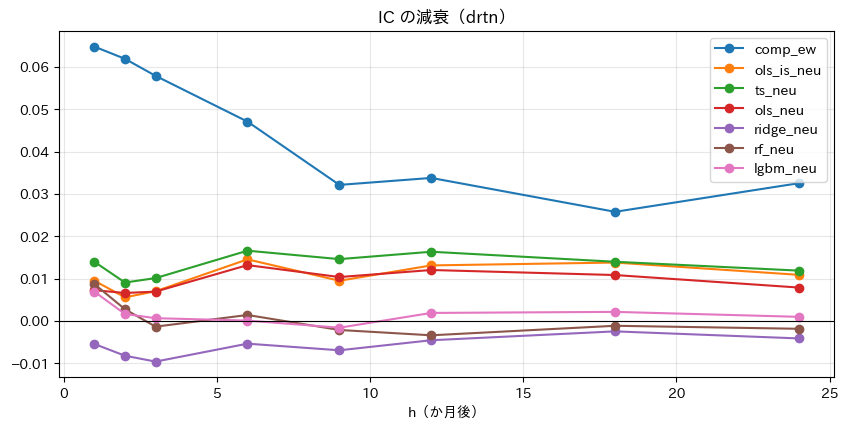

In [5]:
HORIZONS = [1, 2, 3, 6, 9, 12, 18, 24]
decay = {}
for n in ["comp_ew", "ols_is_neu", "ts_neu", "ols_neu", "ridge_neu", "rf_neu", "lgbm_neu"]:
    decay[n] = {h: information_coefficient(scores[n], fwd["drtn"].shift(-(h - 1)), univ).iloc[BURN_IN:].mean() for h in HORIZONS}
decay = pd.DataFrame(decay)
display(decay.T.round(4))
ax = decay.plot(marker="o", figsize=(10, 4.5))
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("h（か月後）")
ax.set_title("IC の減衰（drtn）")
plt.show()

## 4. comp_ew への上乗せ

### 4.1 残差 IC とスパニング回帰

残差 IC: 各月 Blom 化したスコアを Blom 化した `comp_ew` に回帰した残差の IC。スパニング回帰: 等ウェイト 5 分位の Q5 − Q1 月次リターンを `comp_ew` の Q5 − Q1 に回帰（$\alpha$ は年率、t 値は Newey-West ラグ 6）。

In [6]:
EVAL_SINGLE = [v for m in MODELS for v in (m, f"{m}_neu", f"{m}_neu12")]
spreads = {kind: {} for kind in RETURN_KINDS}
for n in ["comp_ew"] + EVAL_SINGLE:
    for kind in RETURN_KINDS:
        spreads[kind][n] = quantile_analysis(scores[n], returns[kind], univ, N_QUANTILES).returns["spread"].iloc[BURN_IN:]
rows = {}
for n in EVAL_SINGLE:
    row = {}
    for kind in RETURN_KINDS:
        rr = ic_summary(information_coefficient(residualize(scores[n], scores["comp_ew"]), fwd[kind], univ).iloc[BURN_IN:])
        row[(kind, "残差 IC")], row[(kind, "残差 t")] = rr["mean"], rr["t_stat"]
        row[(kind, "Q5−Q1 (年率)")] = spreads[kind][n].mean() * 12
        res = nw_ols(spreads[kind][n], spreads[kind]["comp_ew"])
        row.update({(kind, k): v for k, v in res.items()})
    rows[n] = row
span = pd.DataFrame(rows).T
span.columns = pd.MultiIndex.from_tuples(span.columns)
display(span.round(3))
print("comp_ew の Q5−Q1（年率）:", {k: round(v["comp_ew"].mean() * 12, 3) for k, v in spreads.items()})

drtn                                                             srtn                                                          
              残差 IC   残差 t Q5−Q1 (年率) alpha (年率) alpha t   beta beta t     R2  残差 IC   残差 t Q5−Q1 (年率) alpha (年率) alpha t   beta beta t     R2
ols_is       -0.004 -0.538      0.035      0.077   2.169 -0.238 -2.452  0.084 -0.009 -1.169      0.021      0.036   1.173 -0.124 -1.434  0.015
ols_is_neu    0.011  1.872      0.030      0.057   2.555 -0.154 -3.145  0.063  0.003  0.522      0.007      0.017   0.846 -0.088 -1.538  0.013
ols_is_neu12  0.011  1.852      0.036      0.043   1.832 -0.040 -0.728  0.004 -0.000 -0.075      0.000      0.001   0.072 -0.011 -0.177  0.000
ts            0.004  0.462      0.055      0.104   3.005 -0.280 -2.868  0.118 -0.003 -0.440      0.028      0.047   1.674 -0.162 -2.143  0.026
ts_neu        0.015  2.571      0.052      0.087   3.181 -0.200 -3.705  0.104  0.005  0.917      0.019      0.032   1.334 -0.113 -1.912  0.021
ts_neu12      0.014  2.380      0.078      0.096   3.579 -0.098 -1.684  0.025  0.002  0.294      0.033      0.036   1.478 -0.024 -0.367  0.001
ols          -0.004 -0.461      0.032      0.079   2.531 -0.264 -3.900  0.126 -0.009 -1.253      0.006      0.029   1.036 -0.195 -2.948  0.043
ols_neu       0.008  1.532      0.029      0.059   2.445 -0.168 -3.769  0.082 -0.000 -0.048     -0.003      0.009   0.477 -0.106 -1.862  0.019
ols_neu12     0.012  1.978      0.048      0.057   2.417 -0.051 -0.852  0.007 -0.000 -0.049      0.007      0.006   0.308  0.007  0.084  0.000
ridge        -0.016 -1.669      0.003      0.105   3.313 -0.578 -8.378  0.333 -0.018 -2.128      0.004      0.051   1.612 -0.396 -6.100  0.133
ridge_neu     0.000  0.020     -0.004      0.066   2.481 -0.397 -9.775  0.320 -0.008 -1.489     -0.026      0.005   0.224 -0.268 -5.066  0.113
ridge_neu12   0.001  0.078      0.011      0.083   2.948 -0.405 -5.867  0.281 -0.011 -1.896     -0.013      0.019   0.711 -0.277 -4.056  0.103
lasso        -0.016 -1.605      0.010      0.116   2.916 -0.604 -6.352  0.325 -0.022 -2.599     -0.016      0.032   1.022 -0.412 -5.129  0.128
lasso_neu     0.001  0.173     -0.012      0.047   1.705 -0.333 -5.740  0.248 -0.010 -1.915     -0.039     -0.014  -0.606 -0.217 -3.700  0.077
lasso_neu12  -0.002 -0.266     -0.011      0.055   1.956 -0.377 -6.628  0.250 -0.015 -2.438     -0.043     -0.014  -0.625 -0.246 -3.972  0.084
rf           -0.015 -1.511      0.042      0.161   4.257 -0.679 -7.545  0.400 -0.021 -2.366      0.014      0.075   2.542 -0.522 -5.441  0.189
rf_neu        0.010  1.643      0.065      0.135   4.209 -0.401 -6.415  0.305 -0.001 -0.277      0.023      0.057   2.175 -0.291 -4.729  0.126
rf_neu12     -0.001 -0.127      0.033      0.088   3.300 -0.315 -6.825  0.216 -0.012 -2.195     -0.009      0.018   0.766 -0.226 -3.601  0.084
lgbm         -0.006 -0.661      0.051      0.169   4.835 -0.670 -8.773  0.463 -0.013 -1.665      0.022      0.087   2.853 -0.556 -5.810  0.250
lgbm_neu      0.010  1.684      0.035      0.106   4.485 -0.406 -9.312  0.353  0.000  0.038      0.005      0.046   2.128 -0.349 -6.357  0.194
lgbm_neu12    0.001  0.177      0.031      0.095   3.369 -0.363 -6.647  0.268 -0.009 -1.666     -0.010      0.025   0.991 -0.304 -4.580  0.133

comp_ew の Q5−Q1（年率）: {'drtn': 0.176, 'srtn': 0.117}


### 4.2 複合（comp_ew × 候補）と長期保有版

候補は 4 本: Theil–Sen の中立化版（`ts_neu`）とその 12 か月平均（`ts_neu12`）、LightGBM・RF の中立化版。いつもの評価（Q5 EW / CW 超過、Q5 − Q1、税控除後、IC、回転率）を候補単独・論文版・複合について計算する。

In [7]:
schedule = india_tax_schedule(FPI_TYPE)
EVAL = ["comp_ew", "ols_is_neu"] + CANDIDATES + [n for names in BLENDS.values() for n in names]
reports = {}
for n in EVAL:
    reports[n] = compute_alpha_report(n, scores[n], univ, bm, returns, n_quantiles=N_QUANTILES, cw_max_weight=CW_MAX_WEIGHT, tax_schedule=schedule, cost_buy=COST_BUY, cost_sell=COST_SELL, burn_in=BURN_IN, tax_kind="drtn")
tbl = summary_table(reports)
print("drtn（配当込みトータルリターン）")
display(tbl["drtn"].round(3))
print("srtn（固有リターン）")
display(tbl["srtn"].round(3))
display(tbl["共通"].round(3))

drtn（配当込みトータルリターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.130,1.165,0.176,1.152,0.099,1.104,0.085,0.790,0.065,0.482,6.982
ols_is_neu,0.037,0.246,0.030,0.316,0.039,0.320,0.013,0.085,0.009,0.110,1.589
ts_neu,0.052,0.345,0.052,0.544,0.054,0.440,0.027,0.180,0.014,0.158,2.287
ts_neu12,0.054,0.372,0.078,0.823,0.046,0.399,0.036,0.253,0.017,0.194,2.814
rf_neu,0.067,0.451,0.065,0.581,0.062,0.556,0.032,0.222,0.009,0.095,1.375
lgbm_neu,0.052,0.370,0.035,0.336,0.057,0.548,0.015,0.107,0.007,0.074,1.073
comp_ew_90_afats12_10,0.129,1.135,0.172,1.117,0.101,1.096,0.080,0.745,0.066,0.496,7.185
comp_ew_80_afats12_20,0.132,1.155,0.184,1.241,0.102,1.087,0.083,0.764,0.066,0.512,7.412
comp_ew_70_afats12_30,0.124,1.062,0.175,1.237,0.093,1.003,0.077,0.694,0.065,0.528,7.645
comp_ew_90_afats_10,0.128,1.135,0.175,1.141,0.099,1.077,0.082,0.766,0.066,0.499,7.226


srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.101,1.009,0.117,1.071,0.063,0.784,0.055,0.563,0.039,0.380,5.501
ols_is_neu,0.027,0.225,0.007,0.079,0.028,0.307,0.002,0.018,0.003,0.034,0.490
ts_neu,0.034,0.289,0.019,0.217,0.036,0.372,0.009,0.078,0.005,0.054,0.787
ts_neu12,0.036,0.320,0.033,0.379,0.032,0.353,0.019,0.167,0.003,0.042,0.613
rf_neu,0.049,0.430,0.023,0.253,0.044,0.517,0.014,0.129,-0.002,-0.024,-0.343
lgbm_neu,0.040,0.373,0.005,0.055,0.044,0.550,0.002,0.020,-0.001,-0.016,-0.236
comp_ew_90_afats12_10,0.098,0.970,0.112,1.033,0.063,0.762,0.050,0.508,0.039,0.383,5.546
comp_ew_80_afats12_20,0.099,0.974,0.119,1.137,0.062,0.736,0.050,0.508,0.039,0.384,5.562
comp_ew_70_afats12_30,0.090,0.870,0.109,1.083,0.053,0.636,0.044,0.431,0.037,0.381,5.522
comp_ew_90_afats_10,0.099,0.979,0.114,1.070,0.064,0.768,0.054,0.544,0.039,0.386,5.601


指標,回転率 EW,回転率 CW,コストドラッグ,税ドラッグ,短期比率
comp_ew,4.022,4.169,0.017,0.028,0.809
ols_is_neu,2.378,2.293,0.010,0.014,0.781
ts_neu,2.107,2.070,0.009,0.016,0.714
ts_neu12,1.126,0.940,0.005,0.012,0.445
rf_neu,3.232,3.265,0.013,0.020,0.814
lgbm_neu,4.327,4.143,0.018,0.019,0.879
comp_ew_90_afats12_10,4.022,4.156,0.016,0.030,0.808
comp_ew_80_afats12_20,4.007,4.106,0.016,0.031,0.801
comp_ew_70_afats12_30,3.948,4.097,0.016,0.029,0.797
comp_ew_90_afats_10,4.035,4.167,0.017,0.027,0.798


### 4.3 混合比率と指標

横軸は comp_ew の重み（100% = comp_ew 単独）。

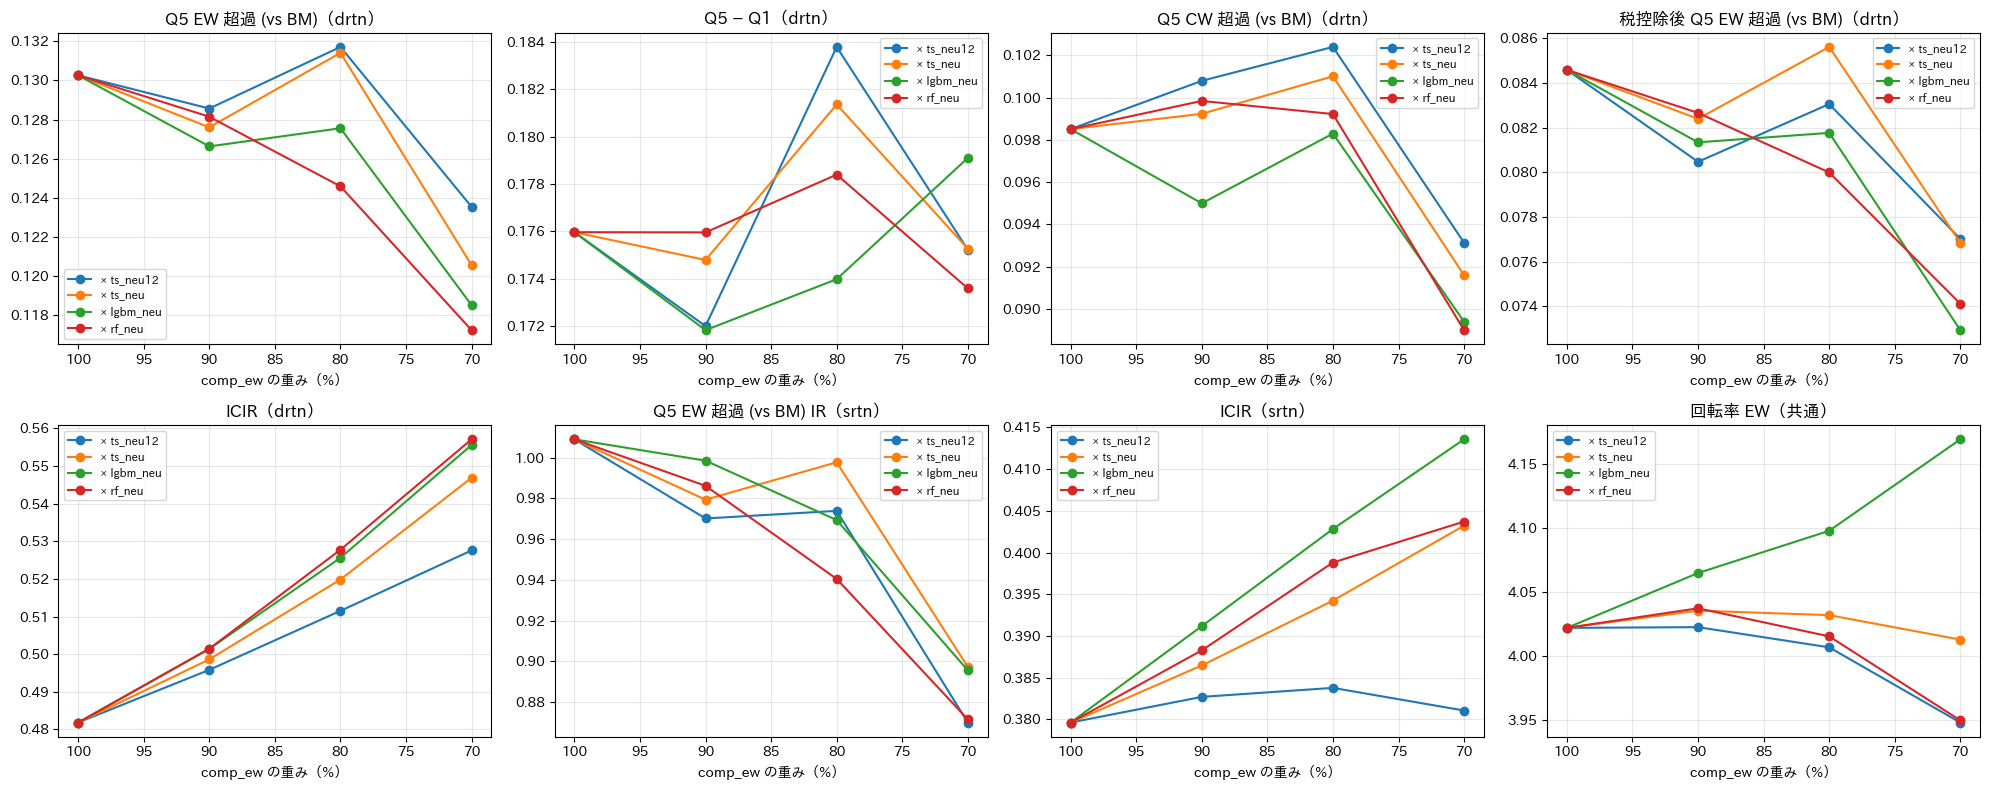

In [8]:
xw = [100] + W
cols = [("drtn", "Q5 EW 超過 (vs BM)"), ("drtn", "Q5 − Q1"), ("drtn", "Q5 CW 超過 (vs BM)"), ("drtn", "税控除後 Q5 EW 超過 (vs BM)"), ("drtn", "ICIR"), ("srtn", "Q5 EW 超過 (vs BM) IR"), ("srtn", "ICIR"), ("共通", "回転率 EW")]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cols):
    for c, names in BLENDS.items():
        ax.plot(xw, [tbl.loc[n, col] for n in ["comp_ew"] + names], marker="o", label=f"× {c}")
    ax.set_title(f"{col[1]}（{col[0]}）")
    ax.set_xlabel("comp_ew の重み（%）")
    ax.invert_xaxis()
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 4.4 累積図

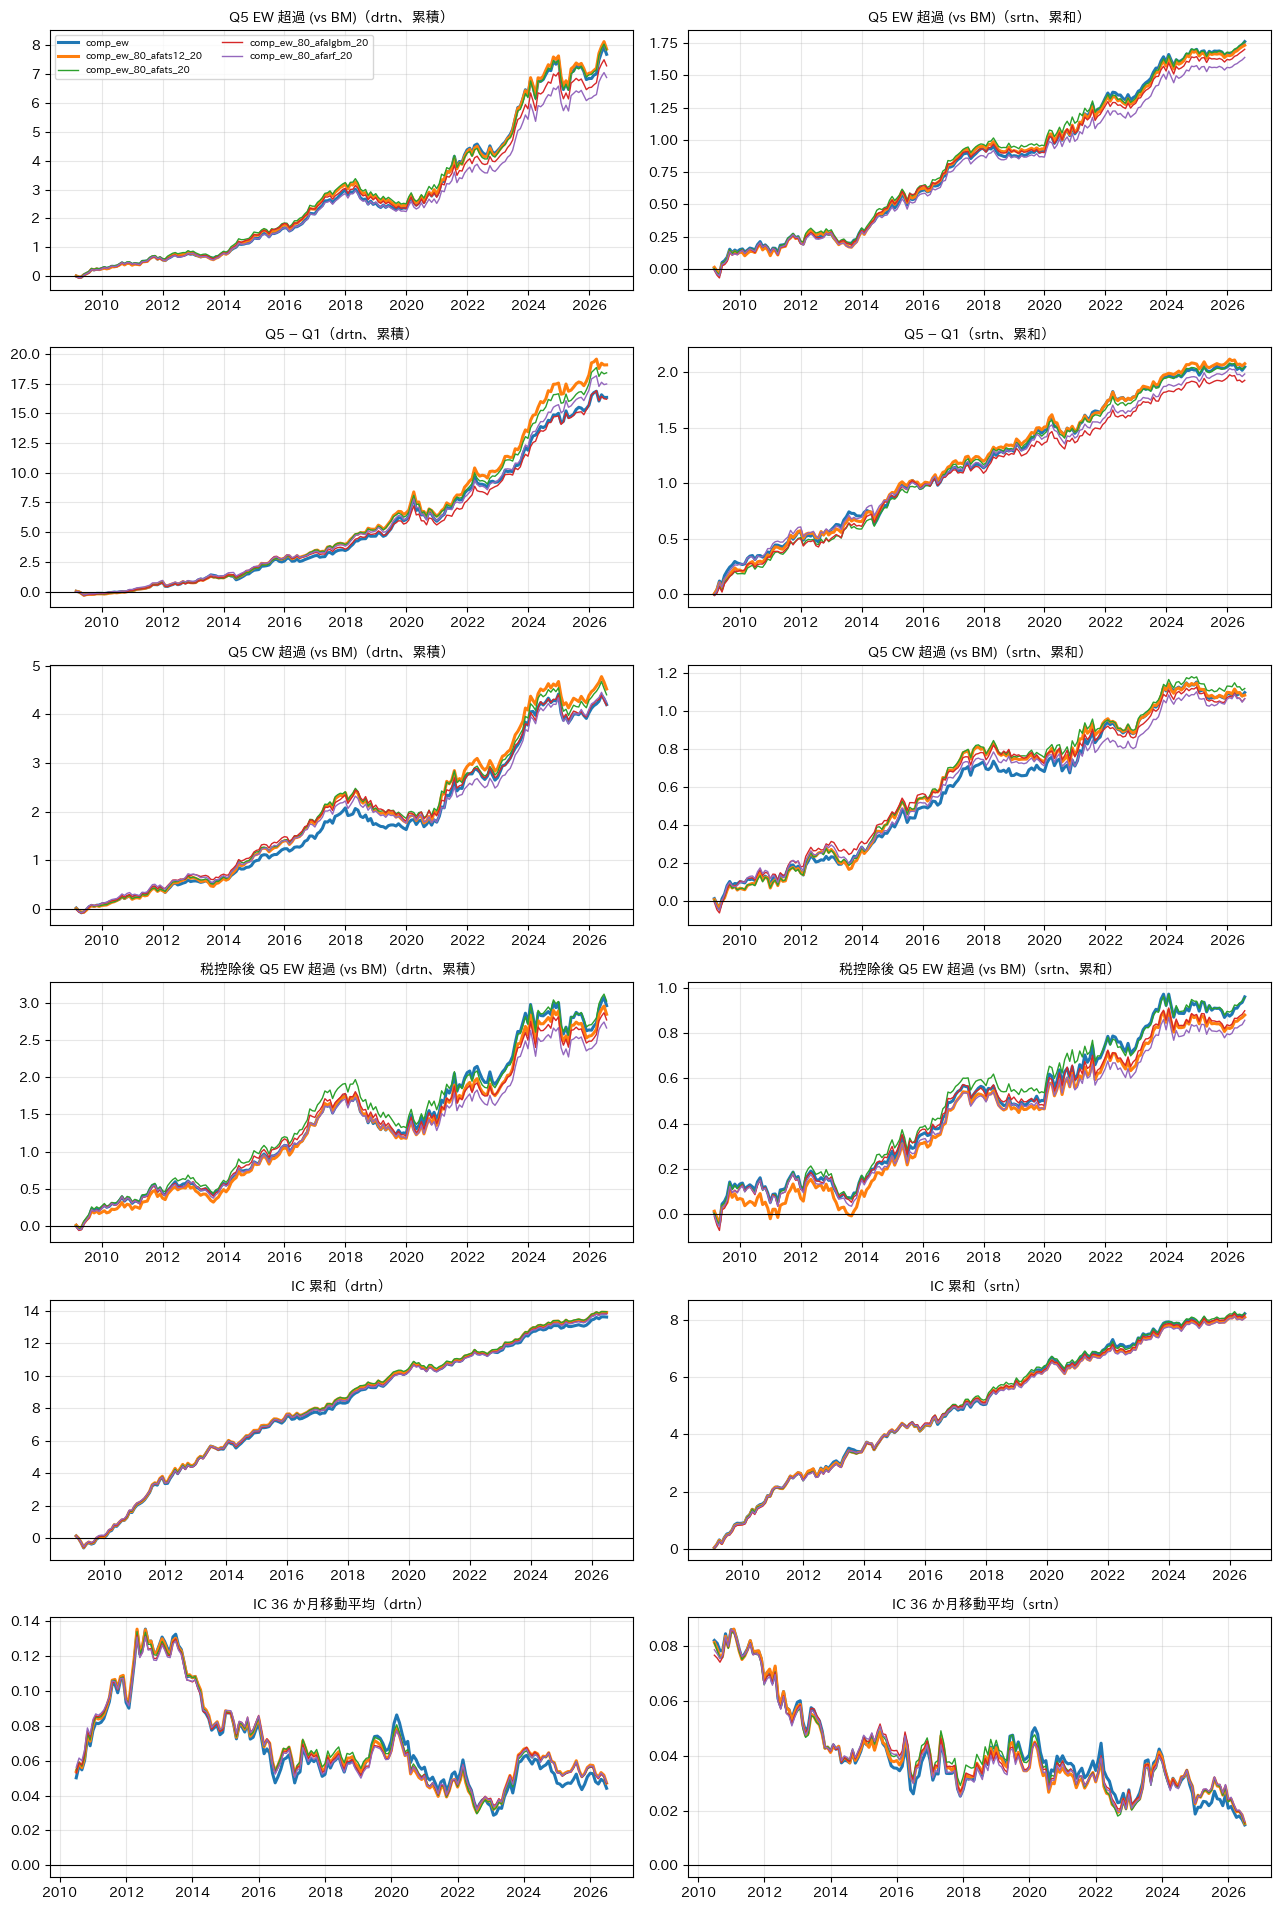

In [9]:
best = ["comp_ew"] + [names[1] for names in BLENDS.values()]
fig = plot_cumulative({n: reports[n] for n in best}, highlight=best[:2])
plt.show()

### 4.5 アルファ横断の棒グラフ（年率、IC は平均）

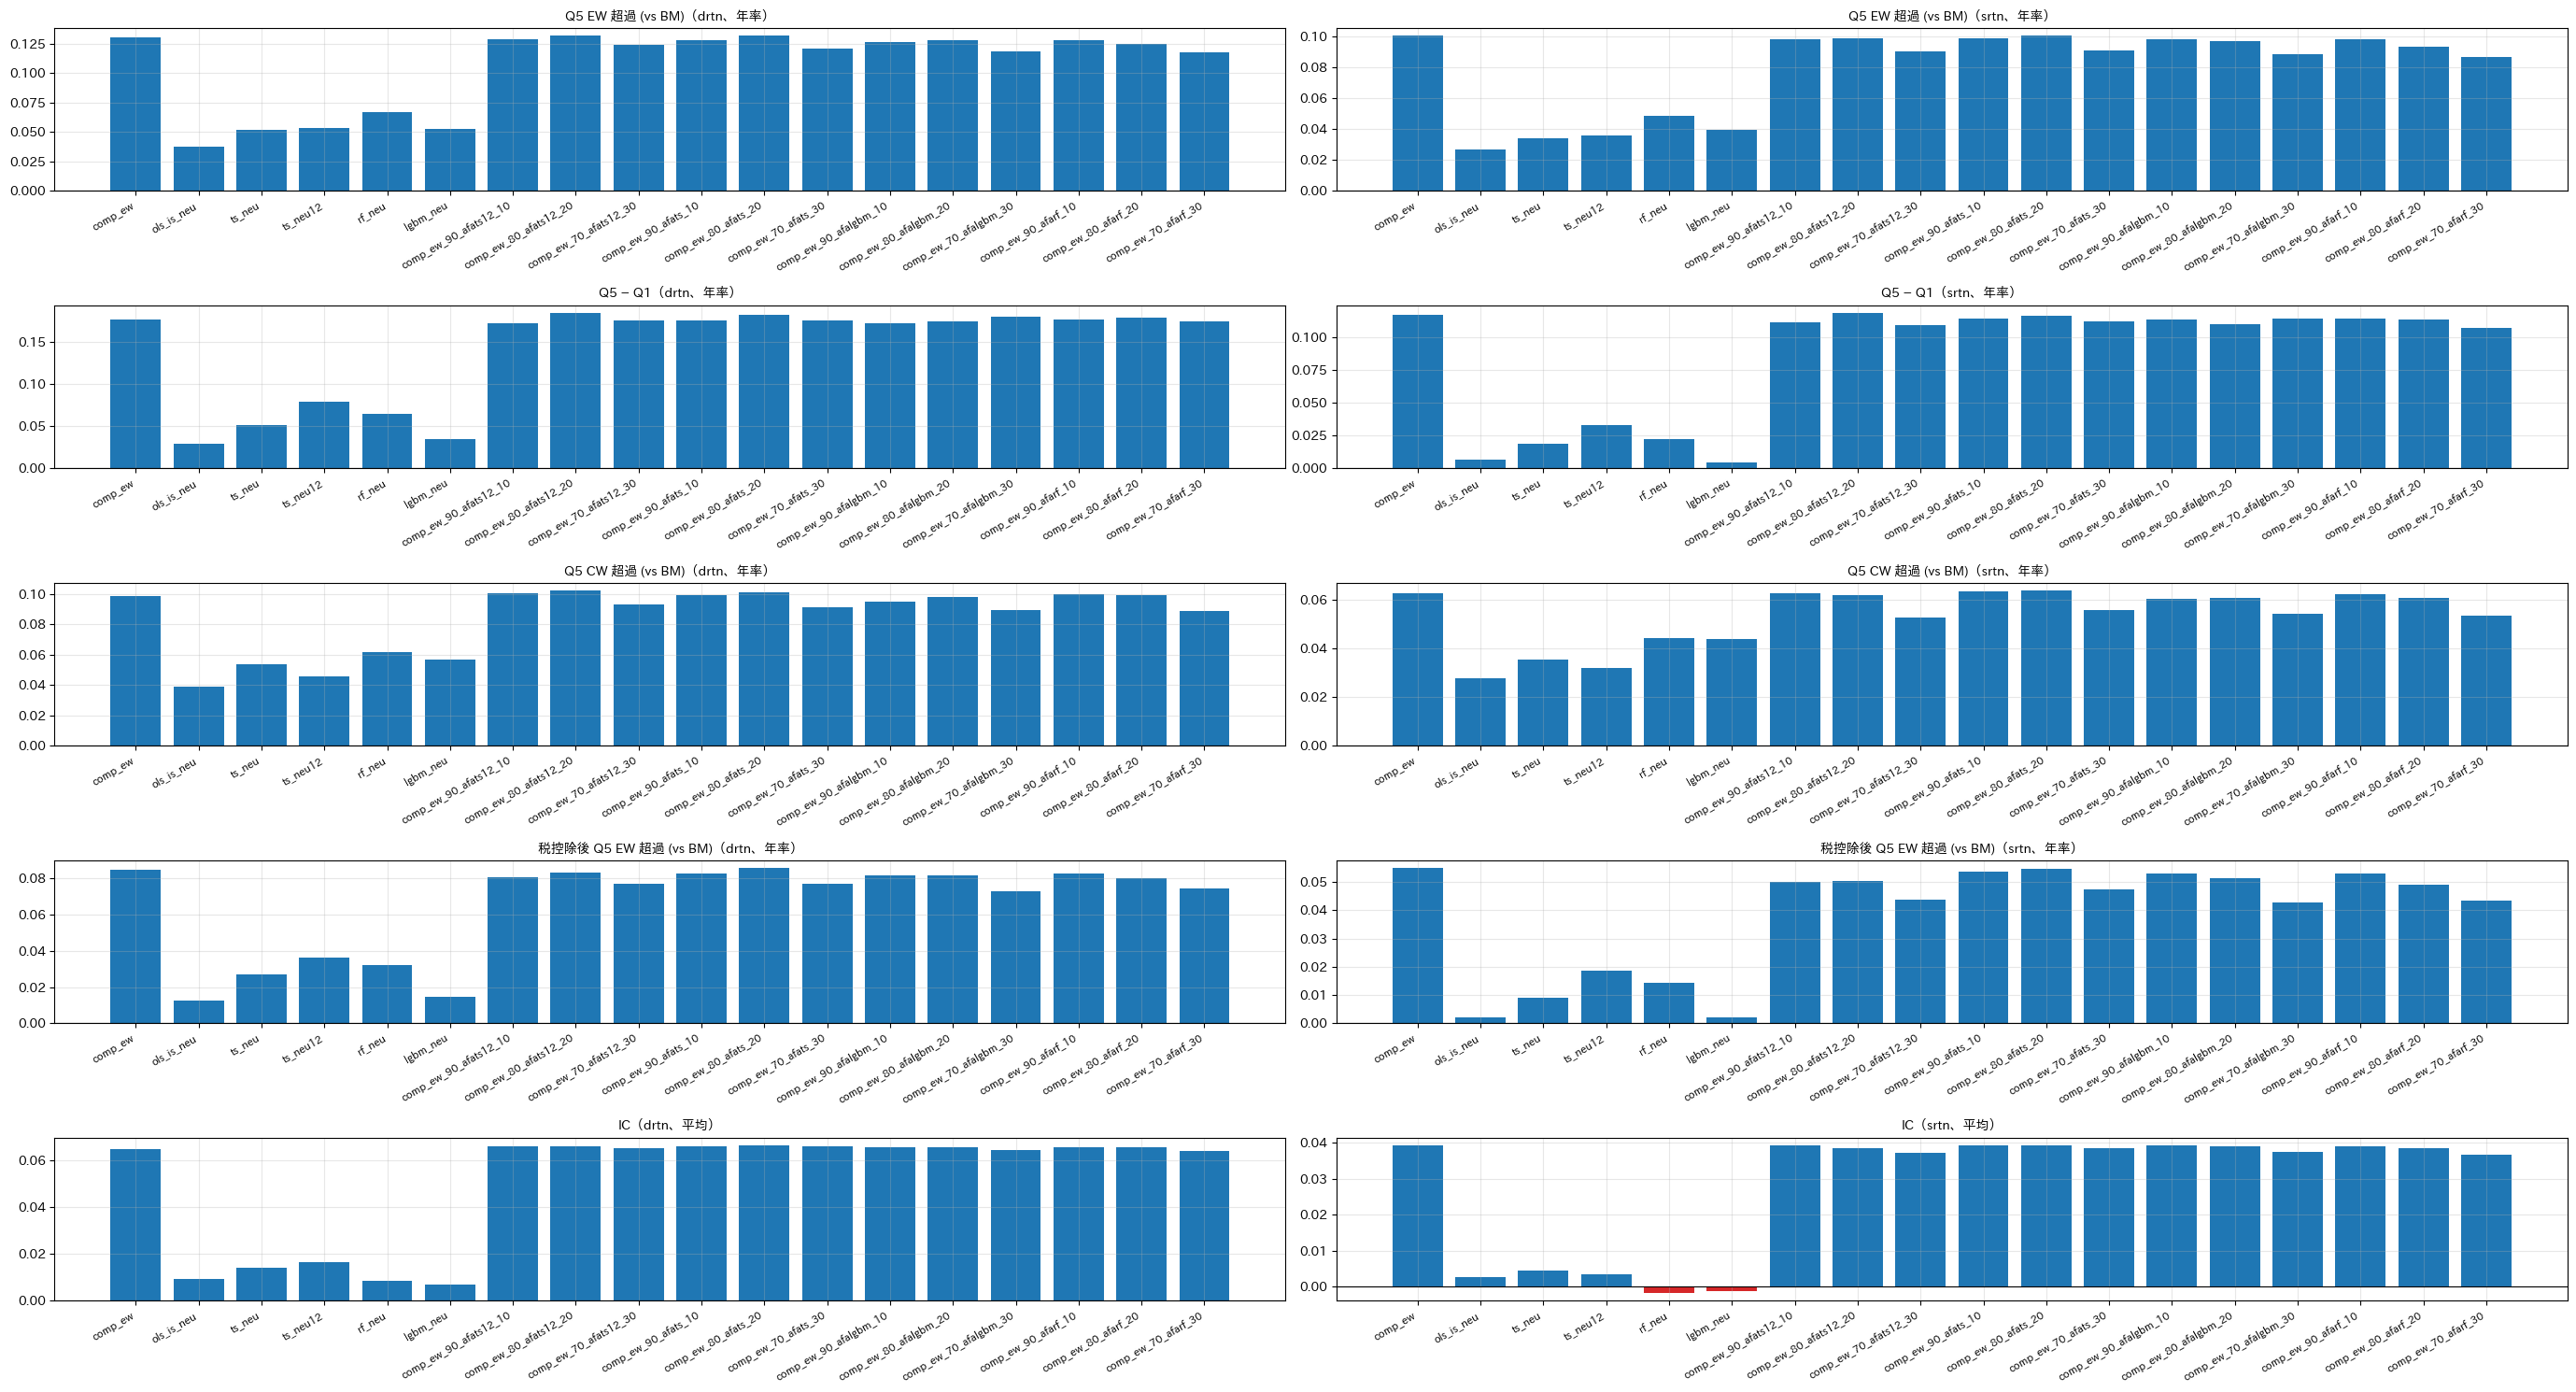

In [10]:
fig = plot_cross_alpha_bars(reports)
plt.show()

### 4.6 期間別（comp_ew 比の差分、srtn）

複合 − comp_ew の Q5 EW 超過・Q5 − Q1（年率）と IC の差。上乗せが特定期間に偏っていないかを見る。

In [11]:
PERIODS = {"2009–2013": ("2009-01", "2013-12"), "2014–2018": ("2014-01", "2018-12"), "2019–2022": ("2019-01", "2022-12"), "2023–2026": ("2023-01", "2026-07")}
base = reports["comp_ew"]
rows = {}
for n in [names[1] for names in BLENDS.values()]:
    rep = reports[n]
    row = {}
    for p, (a, b) in PERIODS.items():
        row[(p, "Δ Q5 EW 超過")] = (rep.series["ew_excess"]["srtn"].loc[a:b].mean() - base.series["ew_excess"]["srtn"].loc[a:b].mean()) * 12
        row[(p, "Δ Q5−Q1")] = (rep.series["spread"]["srtn"].loc[a:b].mean() - base.series["spread"]["srtn"].loc[a:b].mean()) * 12
        row[(p, "Δ IC")] = rep.series["ic"]["srtn"].loc[a:b].mean() - base.series["ic"]["srtn"].loc[a:b].mean()
    rows[n] = row
d = pd.DataFrame(rows).T
d.columns = pd.MultiIndex.from_tuples(d.columns)
display(d.round(3))

2009–2013               2014–2018                 2019–2022                 2023–2026               
                      Δ Q5 EW 超過 Δ Q5−Q1 Δ IC Δ Q5 EW 超過 Δ Q5−Q1   Δ IC Δ Q5 EW 超過 Δ Q5−Q1   Δ IC Δ Q5 EW 超過 Δ Q5−Q1   Δ IC
comp_ew_80_afats12_20     -0.003  -0.010 -0.0      0.011   0.018  0.000     -0.019  -0.011 -0.003      0.002   0.008  0.001
comp_ew_80_afats_20        0.002  -0.023 -0.0      0.013   0.026  0.002     -0.022  -0.010 -0.002      0.004   0.006  0.000
comp_ew_80_afalgbm_20     -0.002  -0.018 -0.0      0.010   0.013  0.000     -0.025  -0.026 -0.002     -0.001   0.002  0.001
comp_ew_80_afarf_20       -0.004  -0.002  0.0      0.003   0.004 -0.002     -0.032  -0.025 -0.002      0.003   0.008  0.001

## 所見

**結論: 中立化した Theil–Sen 版（`ts_neu`）を comp_ew に 20% 混ぜると、Q5 − Q1 と ICIR は少し良くなるが、ロングオンリーの Q5 超過と税控除後はほぼ同じ。** HC と違って劣化はしないが、最適化に回す優先度は中程度。期待していた低回転の効果は、スコアを混ぜる形では残らない。

**1. 生のスコアはサイズのベット。** 7 本とも log 時価総額との順位相関が −0.47〜−0.76、BM 加重平均は −0.5〜−1.5 で、小型株ほど「割安」に出る。IC は −0.023〜+0.002（drtn）で、そのままでは使えない。
サイズ・セクター中立化後は B/P（+0.38〜+0.51）・E/P（+0.43〜+0.60）と正、モメンタムと弱い負（−0.13〜−0.17）、comp_ew とはほぼ無相関（−0.12〜−0.03）。

**2. 単独では弱い。** 中立化版の IC は最大で `ts_neu` 0.014（t 2.3）、12 か月平均の `ts_neu12` 0.017（t 2.8）。comp_ew（0.065、t 7.0）の 1/4 程度。
固有リターン（srtn）の IC は全モデルでほぼゼロか負で、drtn の予測力はスタイル（バリュー）のリターンから来ている。Ridge・Lasso は中立化後も負。

**3. 持続性は Theil–Sen と OLS だけ。** `ts_neu` の IC は 6〜24 か月先でも 0.012〜0.017 を保ち、論文の「効果が数年続く」と整合的。RF・LightGBM は 1 か月の IC（0.007〜0.009）が 2〜3 か月でゼロになる。
木系は時価総額の当てはまりは最も良い（順位相関 0.71〜0.72）が、残差は持続的なミスプライシングではなく短命なノイズに近い。論文の「推定の頑健性（Theil–Sen）が効く」はインドでも当てはまり、柔軟なモデル（Geertsema–Lu 型）は効かなかった。

**4. スパニング回帰のアルファは大きいが、大半は comp_ew とのヘッジ。** 中立化版の α は年 4.7〜13.5%（t 1.7〜4.5）。ただしベータが −0.15〜−0.41 と有意に負で、comp_ew の Q5 − Q1（年 17.6%）× ベータの分がアルファに入っている。
srtn では α が年 −1.4〜+5.7% に縮み、有意なのは `rf_neu`（t 2.2）と `lgbm_neu`（t 2.1）だけ。

**5. 複合（80:20）の結果**

| | Q5 EW 超過 | Q5 − Q1 | Q5 − Q1 IR | Q5 CW 超過 | 税後 Q5 EW 超過 | ICIR | srtn Q5 EW IR | 回転率 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| comp_ew | 13.0% | 17.6% | 1.15 | 9.9% | 8.5% | 0.48 | 1.01 | 402% |
| × `ts_neu` | 13.1% | 18.1% | 1.25 | 10.1% | 8.6% | 0.52 | 1.00 | 403% |
| × `ts_neu12` | 13.2% | 18.4% | 1.24 | 10.2% | 8.3% | 0.51 | 0.97 | 401% |
| × `lgbm_neu` | 12.8% | 17.4% | 1.22 | 9.8% | 8.2% | 0.53 | 0.97 | 410% |
| × `rf_neu` | 12.5% | 17.8% | 1.24 | 9.9% | 8.0% | 0.53 | 0.94 | 402% |

- 比率を 30% に上げると Q5 − Q1 IR（1.24〜1.38）と ICIR（0.53〜0.56）はさらに上がるが、Q5 EW 超過は 11.7〜12.4%、税後は 7.3〜7.7% に下がる。負の相関でロングショートは分散されるが、ロングオンリーの Q5 にはその分が乗らない。
- 期間別（srtn、80:20）では 2014〜2018 年に +0.3〜+1.3%/年（Q5 EW）、2019〜2022 年に −1.9〜−3.2%/年で、2009〜2013 年と 2023 年以降はほぼゼロ。上乗せは安定していない。

**6. 長期保有版は単独では回転率が大きく下がるが、複合では消える。** `ts_neu12` の回転率は 113%/年（`ts_neu` 211%、comp_ew 402%）、短期売却比率は 45%（comp_ew 81%）、税ドラッグは 1.2%/年（comp_ew 2.8%）。
しかし 20% 混ぜたスコアの回転率は 401% で comp_ew と同じ。順位の入れ替わりは comp_ew 側が決めるので、遅いシグナルを混ぜても売買は減らない。

**次の一手**
- 回転率を下げる効果を使うなら、スコアの混合ではなく**ポートフォリオ側**で組む（遅いスリーブを別に保有する、Portfolio-ML のように目標へ部分調整する）。
- 候補は `ts_neu`（持続的、srtn でも負にならない）。bax に 80:20 で回す価値はあるが、期待は Q5 − Q1 と ICIR の小幅な改善まで。
- 財務データは年次なので、四半期の直近 12 か月の値が手に入れば論文に近づき、更新頻度も上がる。Theil–Sen の部分標本数（100）と回数（1 万）の感度も未確認。